In [1]:
import netCDF4 as nc
import glob
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import xrft
from scipy.io import loadmat
import scipy.io as sio
from scipy.special import gamma, kv
from numpy.linalg import inv
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import swot_analysis as swot
from matplotlib import pyplot as plt, animation
import h5py
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
import mpmath as mp
import datetime
from matplotlib import pyplot as plt, animation
import scipy.stats as stats
import pandas as pd
from find_swot_passes import find_swot_pass_segments, select_same_length_segments
import pickle

In [2]:
from swot_spectral_toolbox import (
    select_strips,
    spectrum_compute_1sided,
    outputime,
    build_spectral_dataframe,balanced_fit, matern_spec_new,F_new,ssh_field
)

In [3]:
import warnings
warnings.filterwarnings("ignore")

In [4]:
bbox = [-63, -49, 37, 43] # GS extension
# bbox = [-71,-60,29,35] # Sargasso sea (Oleander)

segments, missing = find_swot_pass_segments(
    data_dir="Science_SWOT_L2_SSH_2.0",
    cycle=3,
    bbox=bbox,
)

selected, n_points = select_same_length_segments(
    segments,
    method="trim",   # or "exact"
    target_n=350,
)

for s in selected:
    print(s["pass"], s["start"], s["stop"], s["n_points"])

46 2505 2855 350
74 2508 2858 350
89 7008 7358 350
102 2508 2858 350
117 7008 7358 350
130 2508 2858 350
145 7008 7358 350
158 2508 2858 350
173 7008 7358 350
201 7008 7358 350
352 2508 2858 350
367 7004 7354 350
380 2508 2858 350
395 7008 7358 350
408 2508 2858 350
423 7008 7358 350
436 2508 2858 350
451 7008 7358 350
464 2508 2858 350
479 7008 7358 350


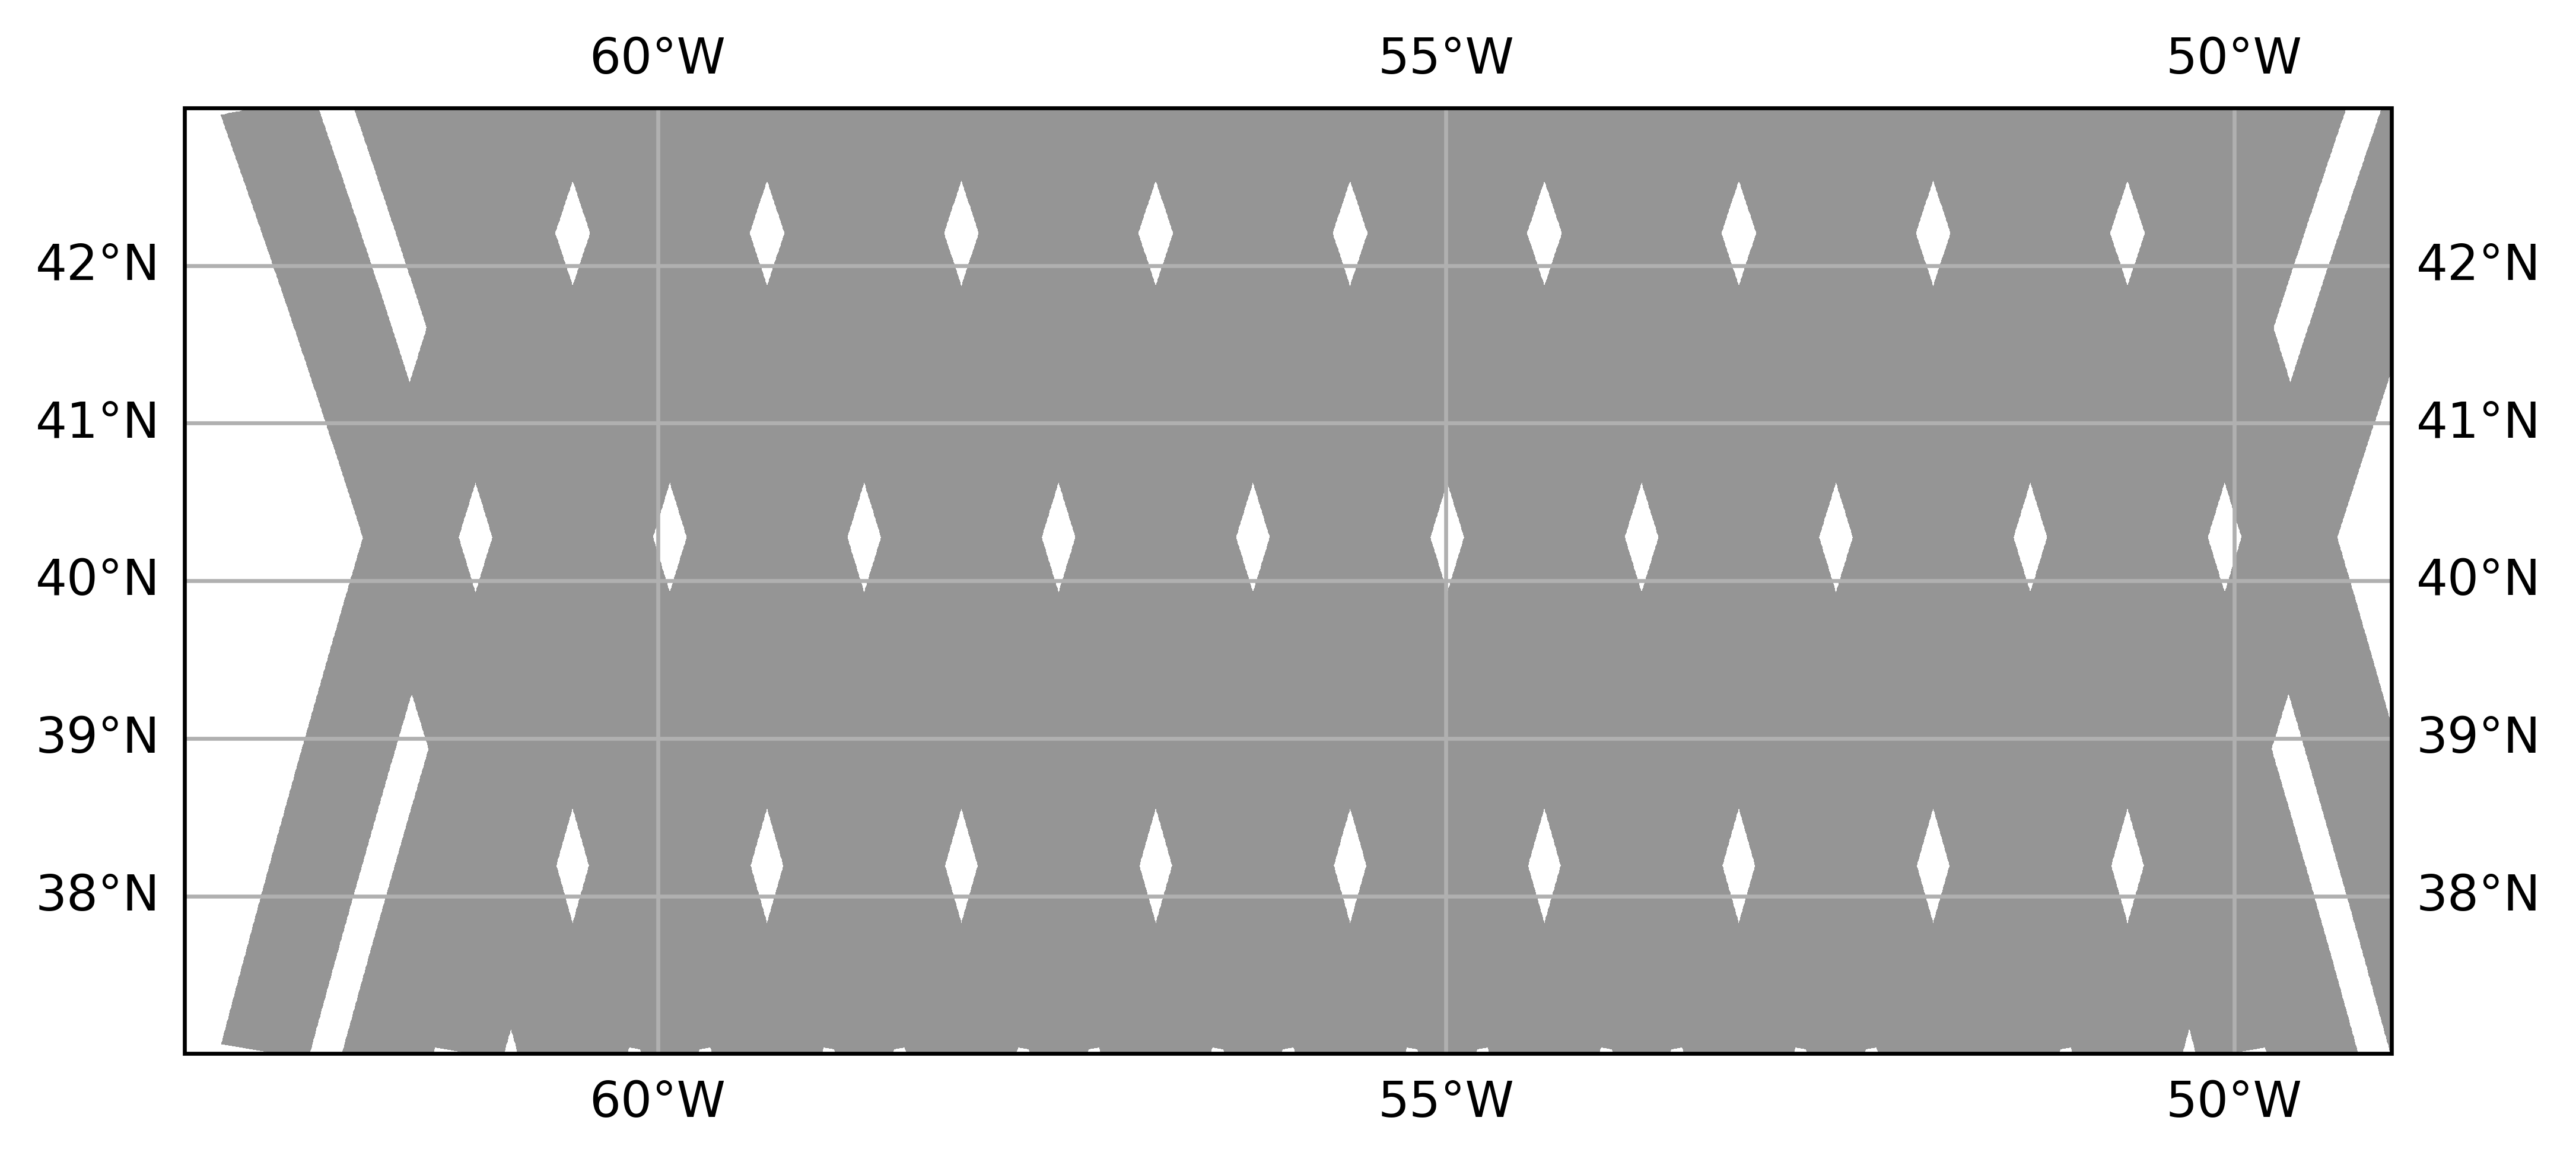

In [7]:
fig = plt.figure(figsize=(8, 10),dpi=600)
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude = 0))# central longitude is 0 by default
ax.add_feature(cfeature.LAND)#, edgecolor='gray')
ax.set_extent(bbox, crs=ccrs.PlateCarree())
gl = ax.gridlines(draw_labels=True, xlocs=np.arange(-180,180,5))
cycle = 3

for s in selected:
    passnumber = s["pass"]
    path = glob.glob('Science_SWOT_L2_SSH_2.0/SWOT_L2_LR_SSH_Basic_'+str(cycle).zfill(3)+'_'+str(passnumber).zfill(3)+'_*.nc')
    if path == []:
        continue   
    first_pass_data = nc.Dataset(path[0], 'r')
    for col_slice in [slice(5, 30), slice(39, 64)]:
        fp_latitude = first_pass_data['latitude'][s["start"]:s["stop"],col_slice]
        fp_longitude = first_pass_data['longitude'][s["start"]:s["stop"],col_slice]
        dummy_color = np.ones_like(fp_longitude) 
        # ssha = first_pass_data['ssha_karin_2']
        cl = plt.pcolormesh(fp_longitude,fp_latitude,0.5*dummy_color,cmap='Greys',shading='auto',vmin = 0,vmax = 1, rasterized=True)

In [7]:
combined = build_spectral_dataframe(selected,'/Volumes/My Passport for Mac/version_D/')

In [9]:
track_length = 350
ssha_tot_combined = pd.DataFrame()
lon_strip_tot = []
lat_strip_tot = []
ssha_mean2side = []
        
for i,s in enumerate(selected): 
    pass_number = s["pass"]
    print(pass_number)
    indx = range(s["start"],s["stop"])
    lat_strip0,lon_strip0,ssha_array0,_,time_array0,\
    good_strips_list0,num_useful_strips0,num_useful_cycles0,cycle_list0 = \
    select_strips(pass_number,indx,track_length)
    _,_,lst_swotime_tot0 = outputime(num_useful_cycles0,time_array0,good_strips_list0)
    
    
    ssha_mean2side0,ssha_array2side_clean,ssha_array2side_anom_clean,lst_swotime_tot_clean = \
    ssh_field(ssha_array0,track_length,good_strips_list0,lst_swotime_tot0,cycle_list0,num_useful_cycles0)
    month_ssh = np.empty((len(lst_swotime_tot_clean),))
    for n, swotime in enumerate(lst_swotime_tot_clean):
        if swotime != 'NaN':
            month_ssh[n] = int(swotime[3:5])
    seasons = ['summer' if m in [6, 7, 8] else
           'fall' if m in [9, 10, 11] else
           'winter' if m in [12, 1, 2] else
           'spring' for m in month_ssh]
    # position = passes_combine_new[dayindx] * np.ones(month_ssh.shape)
    position = pass_number * np.ones(month_ssh.shape)
    # print(position)
    day_indx = i * np.ones(month_ssh.shape)
    ssha2side_combine = pd.DataFrame({
        'month': month_ssh,
        'position': position,
        'dates': lst_swotime_tot_clean,
        'ssha2side': list(ssha_array2side_anom_clean),
        'seasons': seasons,
        'day_indx': day_indx
    })
    ssha_tot_combined = pd.concat([ssha_tot_combined, ssha2side_combine], ignore_index=True)
    lon_strip_tot.append(lon_strip0)
    lat_strip_tot.append(lat_strip0)
    ssha_mean2side.append(ssha_mean2side0)

46
74
89
102
117
130
145
158
173
201
352
367
380
395
408
423
436
451
464
479


In [8]:
# # save for Sargasso Sea (Oleander) region
# with open('Oleander_reselect.pkl', 'wb') as f:
#     pickle.dump({'spectra_tot_combined': combined, 'ssha_tot_combined': ssha_tot_combined, \
#                  'lon_strip_tot': lon_strip_tot, 'lat_strip_tot': lat_strip_tot,\
#                  'ssha_mean2side':ssha_mean2side}, f)

In [10]:
# save for GSExtension region
with open('GSExtension_reselect.pkl', 'wb') as f:
    pickle.dump({'spectra_tot_combined': combined, 'ssha_tot_combined': ssha_tot_combined, \
                 'lon_strip_tot': lon_strip_tot, 'lat_strip_tot': lat_strip_tot,\
                 'ssha_mean2side':ssha_mean2side}, f)

In [9]:
# load data
import pickle
with open("Oleander_reselect.pkl", "rb") as f:
    save_obj = pickle.load(f)

combined = save_obj["spectra_tot_combined"]
ssha_tot_combined = save_obj["ssha_tot_combined"]
lon_strip_tot = save_obj["lon_strip_tot"]
lat_strip_tot = save_obj["lat_strip_tot"]
ssha_mean2side = save_obj['ssha_mean2side']

In [8]:
seasonal = {
    'Winter': [12, 1, 2],
    'Spring': [3, 4, 5],
    'Summer': [6, 7, 8],
    'Fall':   [9, 10, 11]
}

In [12]:
track_length = 350
dx = 2e3
k = np.fft.rfftfreq(track_length, dx)# rfft wave number cpm

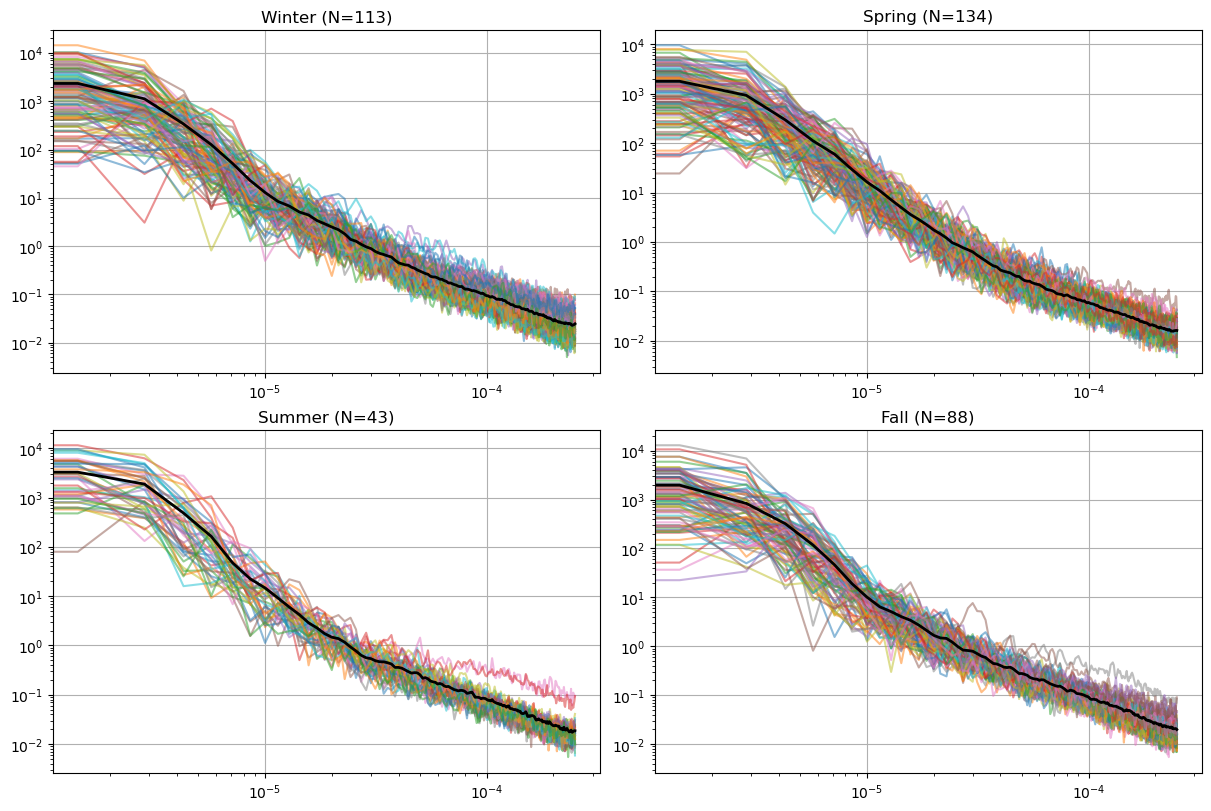

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
axes = axes.flatten()

for i, (season, months) in enumerate(seasonal.items()):
    ax = axes[i]
    df_season = combined[combined['month'].isin(months)]
    # df_season = filtered_spectra[filtered_spectra['month'].isin(months)]
    

    for _, row in df_season.iterrows():
        spectrum = row['spectrum']
        label = f"{row['dates']} (pos {row['position']})"
        ax.loglog(k,spectrum, alpha=0.5, label=label)

    if not df_season.empty:
        seasonal_mean = np.mean(np.vstack(df_season['spectrum'].values), axis=0)
        ax.loglog(k,seasonal_mean, color='black', linewidth=2, label='Seasonal Mean')

    ax.set_title(f"{season} (N={len(df_season)})")
    ax.grid(True)
    # ax.legend(fontsize=7, loc='upper right')
# plt.savefig('../plots/seasonal_kuroshio_extension.png')
plt.show()

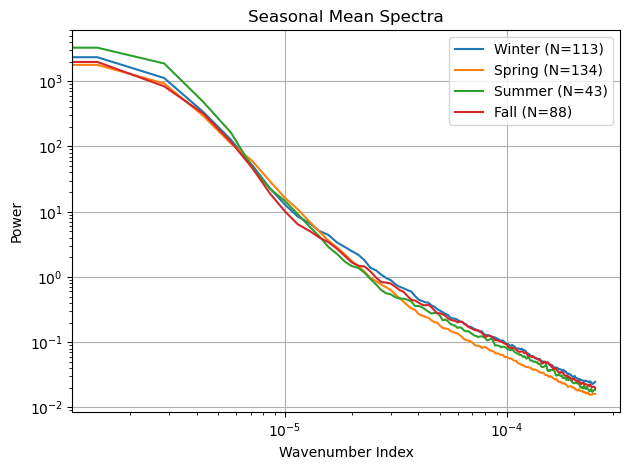

In [13]:
for season, months in seasonal.items():
    df_season = combined[combined['month'].isin(months)]
    # df_season = filtered_spectra[filtered_spectra['month'].isin(months)]
    if not df_season.empty:
        # Stack spectra and compute mean
        seasonal_mean = np.mean(np.vstack(df_season['spectrum'].values), axis=0)
        plt.loglog(k, seasonal_mean, label=f"{season} (N={len(df_season)})")

plt.xlabel("Wavenumber Index")
plt.ylabel("Power")
plt.title("Seasonal Mean Spectra")
plt.legend()
plt.grid(True)
plt.tight_layout()

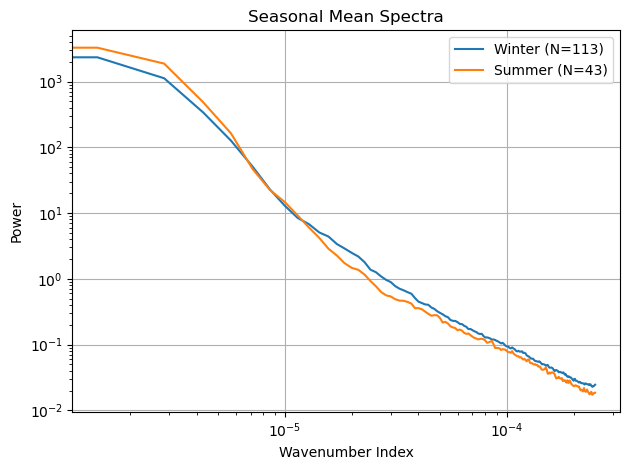

In [14]:
selected_seasons = ['Winter', 'Summer']
for season, months in seasonal.items():
    if season in selected_seasons:
        df_season = combined[combined['month'].isin(months)]
        # df_season = filtered_spectra[filtered_spectra['month'].isin(months)]
        if not df_season.empty:
            # Stack spectra and compute mean
            seasonal_mean = np.mean(np.vstack(df_season['spectrum'].values), axis=0)
            plt.loglog(k, seasonal_mean, label=f"{season} (N={len(df_season)})")

plt.xlabel("Wavenumber Index")
plt.ylabel("Power")
plt.title("Seasonal Mean Spectra")
plt.legend()
plt.grid(True)
plt.tight_layout()